In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal
from scipy.stats import multivariate_normal as mvn
import sklearn
from sklearn.mixture import GaussianMixture as GM
from sklearn.model_selection import KFold



print("Installations Working!")

Installations Working!


In [4]:
priors = [0.4, 0.3, 0.2, 0.1]

cov1 = np.array([[2,   .5], [.5,  2  ]])
cov2 = np.array([[2.5, 1 ], [1,   2.5]])
cov3 = np.array([[4,   1.5], [1.5, 2  ]])
cov4 = np.array([[2,   1.1], [1.1, 5  ]])

# Distance between mu1 and mu2 = sum of their average eigenvalues (trace / 2 in 2-D)
overlap_dist = np.trace(cov1) / 2 + np.trace(cov2) / 2    # 4.5

mu1 = [0, -overlap_dist]
mu2 = [0, 0]
mu3 = [-4, 5]
mu4 = [7, 0]



In [17]:
parameters = [[mu1, cov1], [mu2, cov2], [mu3, cov3], [mu4, cov4]]

def g(mu, C, X_dist):
    return multivariate_normal(mu, C).pdf(X_dist)
def sample(N, seed=5, params=parameters, weights=priors):
    rng = np.random.default_rng(seed)

    K = len(params)
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()               # averaged weights may not sum to exactly 1

    labels = rng.choice(K, size=N, p=weights)
    X = np.zeros((N, len(params[0][0])))

    for c in range(K):
        mu, C = params[c]
        idx = (labels == c)
        X[idx] = rng.multivariate_normal(mu, C, size=idx.sum())

    return labels, X

In [22]:
Y_10, X_10 = sample(10)
Y_100, X_100 = sample(100)
Y_1000, X_1000 = sample(1000)
Y_10000, X_10000 = sample(10000)



### True Distribtion

In [23]:
def plot_GMM(x, y):

    fig = plt.figure(figsize=(9, 8))
    ax = fig.add_subplot()
    markers = {0: 'o', 1: 'o', 2: 'o', 3: 'o'}
    colors  = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green', 3: 'tab:red'}

    for k in [0, 1, 2, 3]:
        pts = x[y == k]
        ax.scatter(pts[:, 0], pts[:, 1],
                marker=markers[k], color=colors[k],
                s=18, alpha=0.5, edgecolors='k', linewidths=0.3,
                label=f"Class {k}")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title("Samples by true class label")
    ax.legend()
    plt.show()

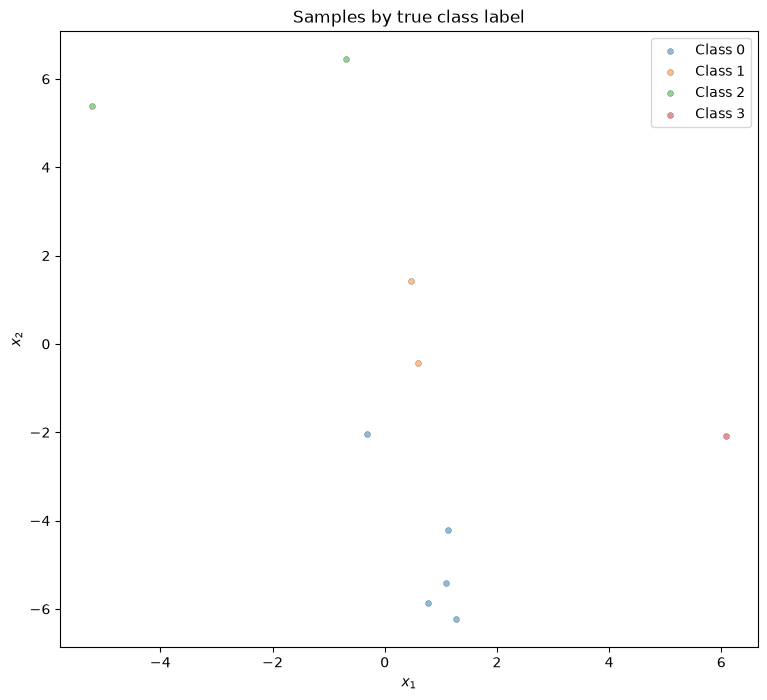

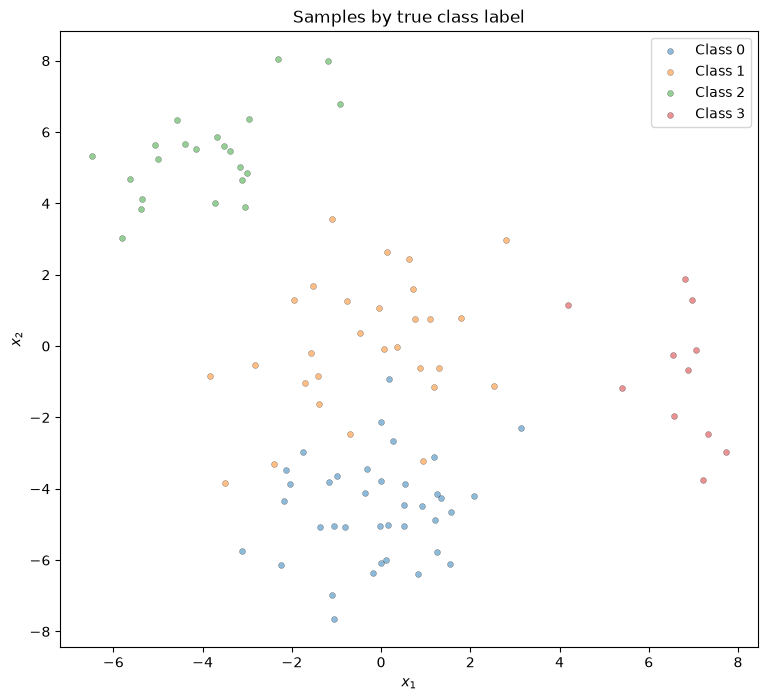

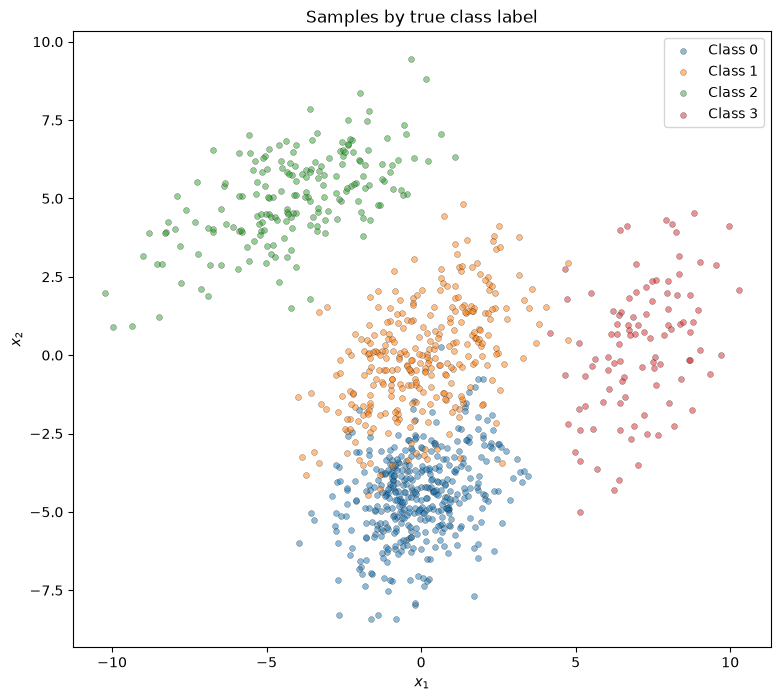

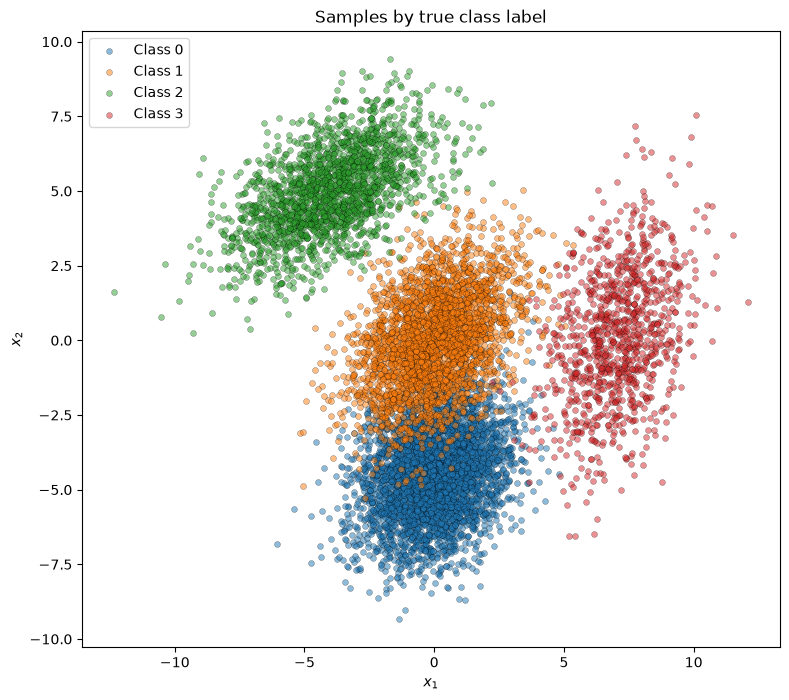

In [24]:
plot_GMM(X_10, Y_10)
plot_GMM(X_100, Y_100)
plot_GMM(X_1000, Y_1000)
plot_GMM(X_10000, Y_10000)

### EM Algorithm

In [9]:
def EM(k, x):

    gm = GM(n_components=k, random_state=0).fit(x)

    avg_ll = gm.score(x)

    return gm, avg_ll

def EM_alg(x, k=10):

    num_folds = 10
    kfold = KFold(n_splits=num_folds, shuffle=True, random_state=0)

    opt_ll = -np.inf
    avg_lls = np.full(k, -np.inf)                 # NEW: avg val LL for each K = 1..k

    for i in range(1, k+1):

        fold_lls = []

        for train, val in kfold.split(x):
            if i > len(train):
                fold_lls = [-np.inf]
                break

            gm = GM(n_components=i, n_init=10, random_state=0).fit(x[train])
            fold_lls.append(gm.score(x[val]))

        avg_ll = np.mean(fold_lls)
        avg_lls[i - 1] = avg_ll                   # NEW: store it

        if avg_ll > opt_ll:
            opt_ll, opt_k = avg_ll, i

    opt_gm = GM(n_components=opt_k, n_init=10, random_state=0).fit(x)

    return opt_gm.means_, opt_gm.covariances_, opt_gm.weights_, opt_k, avg_lls   # CHANGED: + avg_lls

In [10]:
c = 100
sizes = [10, 100, 1000]

D_Mus  = [[], [], []]                        # fitted params (ragged: kept as lists)
D_Covs = [[], [], []]
D_Ps   = [[], [], []]
D_Ks   = np.zeros((c, 3), dtype=int)         # D_Ks[i, j] = selected K
D_LLs  = np.full((c, 3, 10), -np.inf)        # D_LLs[i, j, k] = avg val LL for K = k+1

for i in range(c):

    for j, N in enumerate(sizes):
        _, X_n = sample(N, 1000 * i + N)                 # independent seed per (pass, size)

        mus, covs, ps, K, lls = EM_alg(X_n)              # one call

        D_Mus[j].append(mus)
        D_Covs[j].append(covs)
        D_Ps[j].append(ps)
        D_Ks[i, j] = K
        D_LLs[i, j] = lls

    print(f"Pass {i + 1}:")
    for j, N in enumerate(sizes):
        rates = np.bincount(D_Ks[:i + 1, j], minlength=11)[1:] / (i + 1)
        print(f"  X_{N}: rates K=1..10 = {np.round(rates, 2)} | mean K = {D_Ks[:i + 1, j].mean():.2f}")


print("---------------------FINAL RESULTS---------------------")
for j, N in enumerate(sizes):
    rates = np.bincount(D_Ks[:, j], minlength=11)[1:] / c
    print(f"X_{N}: rates K=1..10 = {np.round(rates, 2)} | mean K = {D_Ks[:, j].mean():.2f}")
print("---------------------FINAL RESULTS---------------------")

Pass 1:
  X_10: rates K=1..10 = [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.] | mean K = 1.00
  X_100: rates K=1..10 = [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.] | mean K = 3.00
  X_1000: rates K=1..10 = [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.] | mean K = 4.00
Pass 2:
  X_10: rates K=1..10 = [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.] | mean K = 1.00
  X_100: rates K=1..10 = [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.] | mean K = 3.00
  X_1000: rates K=1..10 = [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.] | mean K = 4.00
Pass 3:
  X_10: rates K=1..10 = [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.] | mean K = 1.00
  X_100: rates K=1..10 = [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.] | mean K = 3.00
  X_1000: rates K=1..10 = [0.   0.   0.   0.67 0.33 0.   0.   0.   0.   0.  ] | mean K = 4.33
Pass 4:
  X_10: rates K=1..10 = [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.] | mean K = 1.00
  X_100: rates K=1..10 = [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.] | mean K = 3.00
  X_1000: rates K=1..10 = [0.   0.   0.   0.75 0.25 0.   0.   0.   0.   0.  ] | mean K = 4.25
Pass 5:
  X_10: rates K=1..10 = [1. 0. 0. 0. 0. 0. 0

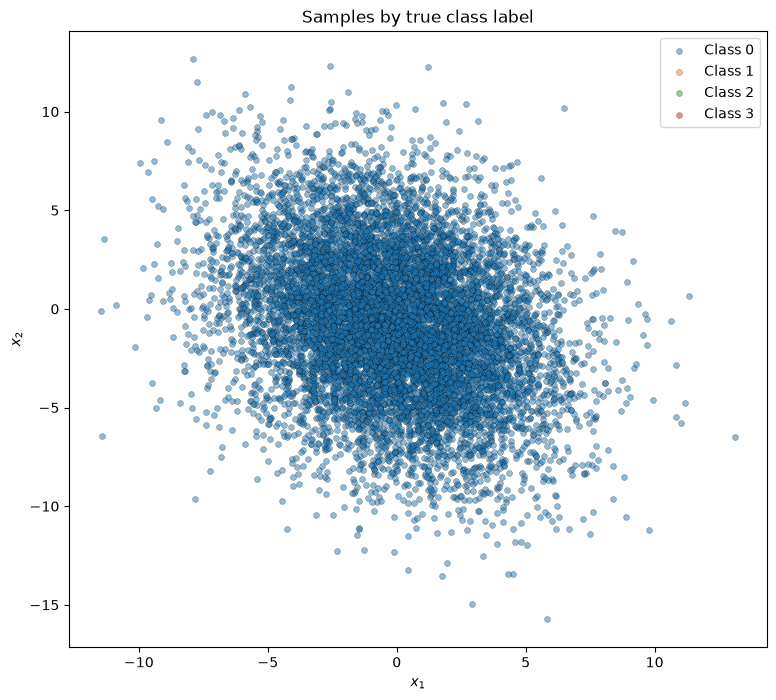

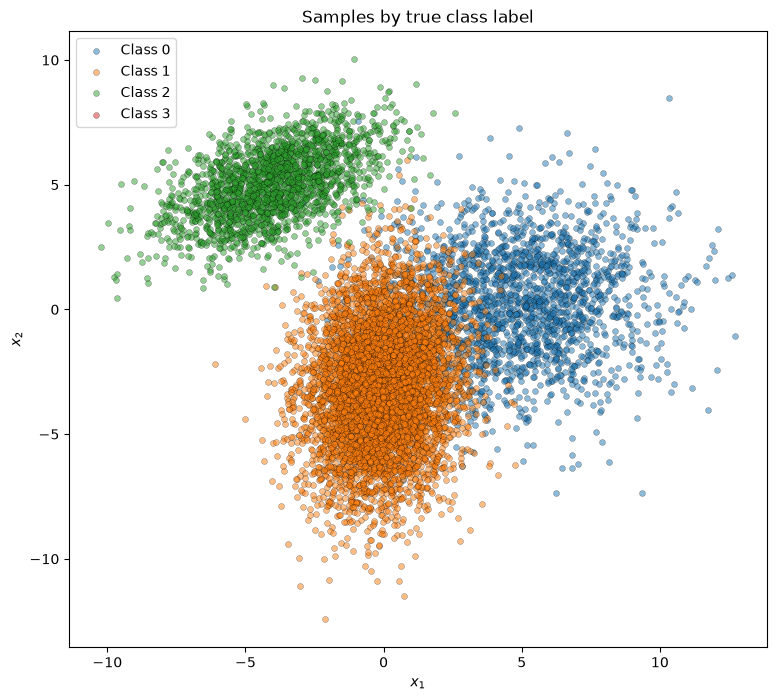

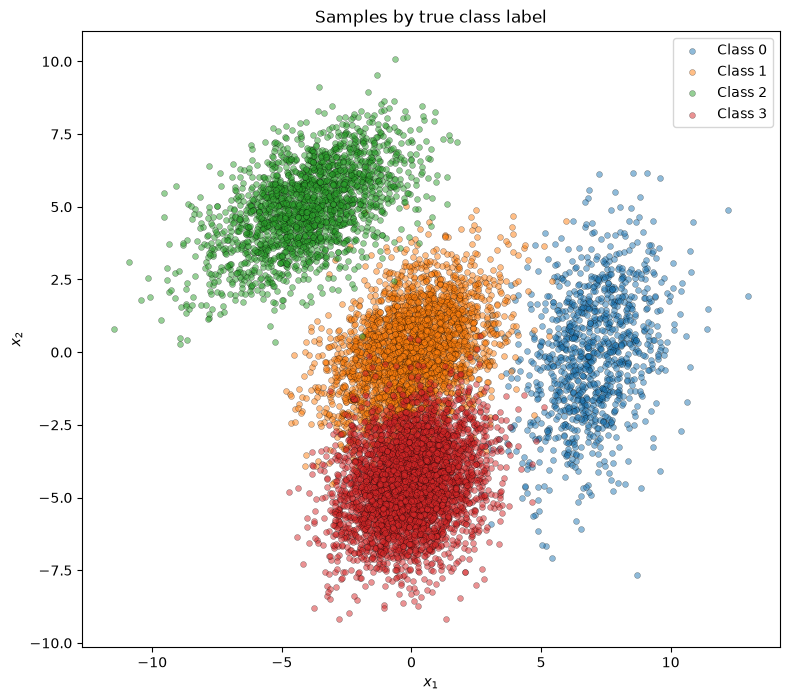

In [15]:
from scipy.optimize import linear_sum_assignment

def mode_averages(j):
    Ks = D_Ks[:, j]
    K_star = np.bincount(Ks).argmax()                       # mode K
    runs = np.where(Ks == K_star)[0]

    ref = D_Mus[j][runs[0]]                                  # reference: first mode run
    mus, covs, ps = [], [], []
    for r in runs:
        cost = ((D_Mus[j][r][:, None, :] - ref[None, :, :]) ** 2).sum(-1)   # ||mu_r,a - ref_b||^2
        a, b = linear_sum_assignment(cost)
        order = a[np.argsort(b)]                             # component of run r matched to ref k
        mus.append(D_Mus[j][r][order]); covs.append(D_Covs[j][r][order]); ps.append(D_Ps[j][r][order])

    return K_star, len(runs), np.mean(mus, 0), np.mean(covs, 0), np.mean(ps, 0)

sizes = [10, 100, 1000]
for j, N in enumerate(sizes):
    K_star, n, mu_bar, cov_bar, p_bar = mode_averages(j)
    fitted = list(zip(mu_bar, cov_bar))              # [[mu_k, Sigma_k], ...]

    labels_fit, X_fit = sample(10000, seed=0, params=fitted, weights=p_bar)
    plot_GMM(X_fit, labels_fit)

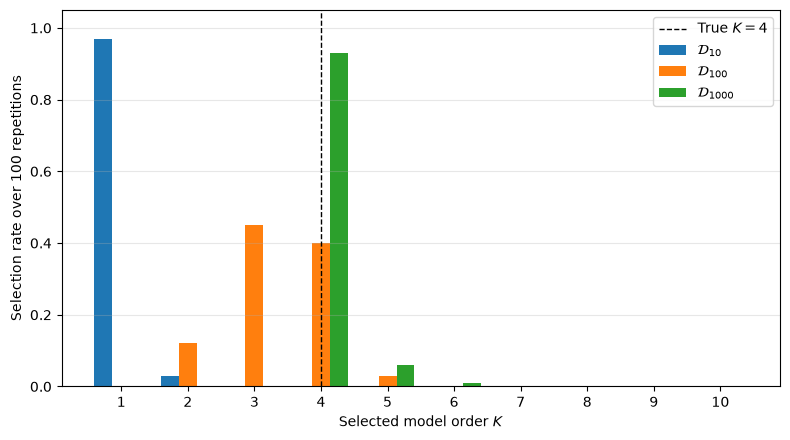

In [26]:
rates = np.array([np.bincount(D_Ks[:, j], minlength=11)[1:] / c for j in range(len(sizes))])

Ks = np.arange(1, 11)
w = 0.27

fig, ax = plt.subplots(figsize=(8, 4.5))
for j, N in enumerate(sizes):
    ax.bar(Ks + (j - 1) * w, rates[j], width=w, label=f"$\\mathcal{{D}}_{{{N}}}$")
ax.axvline(4, color='k', linestyle='--', linewidth=1, label='True $K = 4$')

ax.set_xlabel("Selected model order $K$")
ax.set_ylabel(f"Selection rate over {c} repetitions")
ax.set_xticks(Ks)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()